In [8]:
#julia -t 4

using Plots
using Random, Statistics, Distributions
using SparseArrays
using LinearAlgebra
using DifferentialEquations
using StatsPlots 

using Statistics 
using Distributions, Random, Plots, StatsBase  
using Base.Threads



include("../Project_with_Jon/GPs.jl")
include("../Project_with_Jon/functions.jl")
include("../Project_with_Jon/myfuncs.jl")
include("../Project_with_Jon/integrators.jl")
include("../Project_with_Jon/util_shoji.jl")


simulate_pf_selforg (generic function with 1 method)

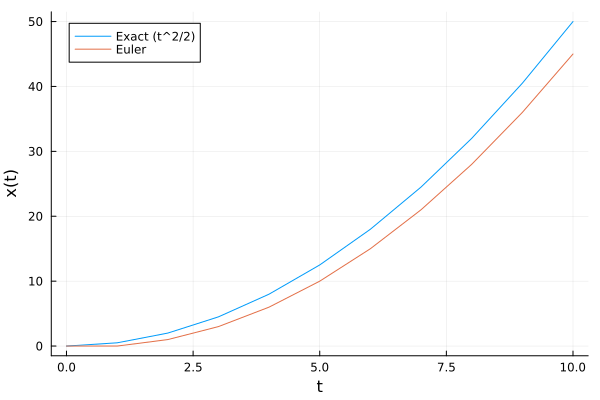

In [9]:
u0 = 0.0
dt = 1.0
T = 10
tspan = 0:dt:T

function reaction(u, p, t)
    return t
end

sol = exact(reaction, u0, tspan, Tsit5(), 1e-10, 1e-10)

numsol, _ = numerical_integration(
    reaction,
    Euler,
    u0,
    dt,
    length(tspan),
    1
)

plot(tspan, sol,
    label="Exact (t^2/2)",
    xlabel="t",
    ylabel="x(t)"
)

plot!(tspan, numsol,
    label="Euler"
)



obs_noise:10.0
X_test[0.0, 0.02004008016032064, 0.04008016032064128, 0.06012024048096192, 0.08016032064128256, 0.10020040080160321, 0.12024048096192384, 0.1402805611222445, 0.16032064128256512, 0.18036072144288579, 0.20040080160320642, 0.22044088176352705, 0.24048096192384769, 0.2605210420841683, 0.280561122244489, 0.30060120240480964, 0.32064128256513025, 0.3406813627254509, 0.36072144288577157, 0.3807615230460922, 0.40080160320641284, 0.42084168336673344, 0.4408817635270541, 0.46092184368737477, 0.48096192384769537, 0.501002004008016, 0.5210420841683366, 0.5410821643286573, 0.561122244488978, 0.5811623246492986, 0.6012024048096193, 0.6212424849699398, 0.6412825651302605, 0.6613226452905812, 0.6813627254509018, 0.7014028056112225, 0.7214428857715431, 0.7414829659318637, 0.7615230460921844, 0.781563126252505, 0.8016032064128257, 0.8216432865731463, 0.8416833667334669, 0.8617234468937875, 0.8817635270541082, 0.9018036072144289, 0.9218436873747495, 0.9418837675350702, 0.9619238476953907,

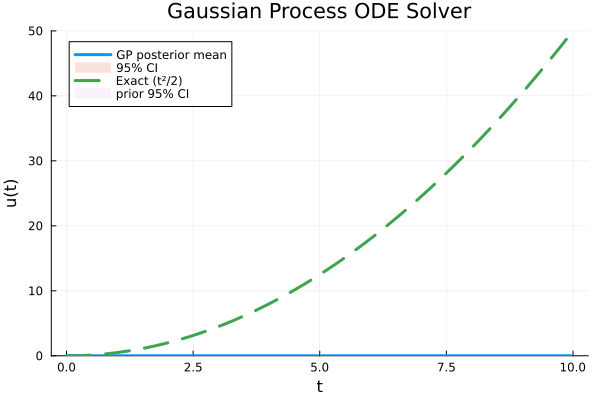

In [4]:
using LinearAlgebra
using Plots



ℓ = 0.1
σf = 0.001
prior_mean = 0.0
obs_noise = (dt)*2

println("obs_noise:",obs_noise)

# =====================================================
# Cov(L_i,L_j)
#
# L_i u =
# (u(t_i+dt)-u(t_i))/dt
# =====================================================

function K_LL(ts; dt, ℓ=1.0, σf=1.0)

    n = length(ts)

    K = zeros(n,n)

    for i in 1:n
        for j in 1:n

            ti = ts[i]
            tj = ts[j]

            K[i,j] =
                (
                    rbf_kernel(ti+dt,tj+dt; ℓ=ℓ, σf=σf)
                    -
                    rbf_kernel(ti+dt,tj; ℓ=ℓ, σf=σf)
                    -
                    rbf_kernel(ti,tj+dt; ℓ=ℓ, σf=σf)
                    +
                    rbf_kernel(ti,tj; ℓ=ℓ, σf=σf)
                ) / dt^2

        end
    end

    K
end

# =====================================================
# Observation covariance
#
# observations:
#
# [u(0),
#  L0u,
#  L1u,
#  ...]
# =====================================================

function build_observation_covariance(ts;
                                      dt,
                                      ℓ,
                                      σf)

    n = length(ts)

    K = zeros(n+1,n+1)

    #
    # Cov(u(0),u(0))
    #

    K[1,1] =
        rbf_kernel(
            0.0,
            0.0;
            ℓ=ℓ,
            σf=σf
        )

    #
    # Cov(u(0),Lj)
    #

    for j in 1:n

        tj = ts[j]

        K[1,j+1] =
            (
                rbf_kernel(
                    0.0,
                    tj+dt;
                    ℓ=ℓ,
                    σf=σf
                )
                -
                rbf_kernel(
                    0.0,
                    tj;
                    ℓ=ℓ,
                    σf=σf
                )
            ) / dt

        K[j+1,1] =
            K[1,j+1]

    end

    #
    # Cov(Li,Lj)
    #

    K[2:end,2:end] .=
        K_LL(
            ts;
            dt=dt,
            ℓ=ℓ,
            σf=σf
        )

    K
end

# =====================================================
# Cov(u(t),L_j)
# =====================================================

function K_starL(X_test,
                 ts;
                 dt,
                 ℓ=1.0,
                 σf=1.0)

    m = length(X_test)
    n = length(ts)

    K = zeros(m,n)

    for i in 1:m
        for j in 1:n

            t = X_test[i]
            tj = ts[j]

            K[i,j] =
                (
                    rbf_kernel(t,tj+dt; ℓ=ℓ, σf=σf)
                    -
                    rbf_kernel(t,tj; ℓ=ℓ, σf=σf)
                ) / dt

        end
    end

    K
end



# =====================================================
# Cross covariance
#
# Cov(u(t), observations)
# =====================================================

function build_cross_covariance(X_test,
                                ts;
                                dt,
                                ℓ,
                                σf)

    m = length(X_test)
    n = length(ts)

    K = zeros(m,n+1)

    #
    # Cov(u(t),u(0))
    #

    for i in 1:m

        K[i,1] =
            rbf_kernel(
                X_test[i],
                0.0;
                ℓ=ℓ,
                σf=σf
            )

    end

    #
    # Cov(u(t),Lj)
    #

    K[:,2:end] .=
        K_starL(
            X_test,
            ts;
            dt=dt,
            ℓ=ℓ,
            σf=σf
        )

    K
end

# =====================================================
# ODE
#
# u'(t)=t
#
# exact:
# u(t)=t²/2
# =====================================================


t_obs =
    collect(0:dt:10)

t_obs = t_obs[2:end]

rhs =
    collect(t_obs)


#
# observations:
#
# u(0)=0
#
# (u(t_i+dt)-u(t_i))/dt = t_i
#

y =
    vcat(
        [0.0],
        rhs
    )

#y .-= prior_mean




# =====================================================
# Posterior
# =====================================================

X_test =
    collect(
        range(
            0,
            10,
            length=500
        )
    )

println("X_test", X_test)
println("t_obs:", t_obs)

println("y:", y)

K =
    build_observation_covariance(
        t_obs;
        dt=dt,
        ℓ=ℓ,
        σf=σf
    )

#K += 1e-10I


#Observation Noise
K[2:end,2:end] += obs_noise .* I

Ks =
    build_cross_covariance(
        X_test,
        t_obs;
        dt=dt,
        ℓ=ℓ,
        σf=σf
    )

Kss =
    kernel_matrix(
        X_test,
        X_test;
        ℓ=ℓ,
        σf=σf
    )

m_y = vcat([prior_mean],  zeros(length(t_obs)))
println("m_y:", m_y)
m_x = fill(prior_mean, length(X_test))
println("m_x:", m_x.size)
println(" Ks * (K \\ (y-m_y)):", (Ks * (K \ (y-m_y))).size)

μ =   
 m_x + Ks * (K \ (y-m_y))




Σ =
    Kss -
    Ks * (K \ Ks')

std =
    sqrt.(max.(diag(Σ),0))

# =====================================================
# Exact solution
# =====================================================

u_exact(t) =
    t^2 / 2


# =====================================================
# Plot
# =====================================================

plot(
    X_test,
    μ,
    lw=3,
    ylim=(0, 50),
    label="GP posterior mean"
)

plot!(
    X_test,
    μ .+ 1.96 .* std,
    fillrange=
        μ .- 1.96 .* std,
    fillalpha=0.2,
    linealpha=0,
    label="95% CI"
)

plot!(
    X_test,
    u_exact.(X_test),
    lw=3,
    ls=:dash,
    label="Exact (t²/2)"
)

μ_prior = zeros(length(X_test))

Kss = kernel_matrix(
    X_test,
    X_test;
    ℓ=ℓ,
    σf=σf
)

std_prior = sqrt.(diag(Kss))


μ_prior = fill(prior_mean, length(X_test))

plot!(
    X_test,
    μ_prior .+ 1.96 .* std_prior,
    fillrange = μ_prior .- 1.96 .* std_prior,
    fillalpha = 0.1,
    linealpha = 0,
    label = "prior 95% CI"
)

xlabel!("t")
ylabel!("u(t)")
title!("Gaussian Process ODE Solver")

display(current())

In [5]:
ℓ_grid = [0.1, 0.5, 1.0, 3.0, 5.0, 10.0, 50, 100]

σf_grid = [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100, 1000]

prior_mean = 0.0

scores = zeros(length(ℓ_grid), length(σf_grid))

# ==========================================
# Grid Search
# ==========================================

for (i, ℓ) in enumerate(ℓ_grid)
    for (j, σf) in enumerate(σf_grid)

        scores[i, j] =
            log_marginal_extended2(
                t_obs,
                y;
                dt=dt,
                ℓ=ℓ,
                σf=σf,
                prior_mean=prior_mean,
                prior_noise=obs_noise
            )

    end
end

# ==========================================
# 全スコア表示
# ==========================================

for (j, σf) in enumerate(σf_grid)

    println()
    println("========================================")
    println("σf = ", σf)
    println("========================================")

    println(rpad("ℓ", 10), "score")

    for (i, ℓ) in enumerate(ℓ_grid)
        println(rpad(string(ℓ), 10), round(scores[i, j], digits=4))
    end
end

# ==========================================
# Best parameters
# ==========================================

best_linear_idx = argmax(scores)
best_i, best_j = Tuple(CartesianIndices(scores)[best_linear_idx])

best_ℓ = ℓ_grid[best_i]
best_σf = σf_grid[best_j]

println()
println("Best parameters")
println("----------------")
println("best ℓ    = ", best_ℓ)
println("best σf   = ", best_σf)
println("best score = ", scores[best_i, best_j])


σf = 0.01
ℓ         score
0.1       -6.7042
0.5       -6.7042
1.0       -6.7042
3.0       -6.7042
5.0       -6.7042
10.0      -6.7042
50.0      -6.7042
100.0     -6.7042

σf = 0.03
ℓ         score
0.1       -7.8028
0.5       -7.8028
1.0       -7.8028
3.0       -7.8028
5.0       -7.8028
10.0      -7.8028
50.0      -7.8028
100.0     -7.8028

σf = 0.1
ℓ         score
0.1       -9.0066
0.5       -9.0066
1.0       -9.0066
3.0       -9.0066
5.0       -9.0067
10.0      -9.0068
50.0      -9.0068
100.0     -9.0068

σf = 0.3
ℓ         score
0.1       -10.1034
0.5       -10.1034
1.0       -10.1034
3.0       -10.1035
5.0       -10.104
10.0      -10.105
50.0      -10.1054
100.0     -10.1054

σf = 1.0
ℓ         score
0.1       -11.2875
0.5       -11.2875
1.0       -11.2875
3.0       -11.2883
5.0       -11.2935
10.0      -11.3045
50.0      -11.309
100.0     -11.3093

σf = 3.0
ℓ         score
0.1       -12.2206
0.5       -12.2206
1.0       -12.2206
3.0       -12.2254
5.0       -12.2685
10.0      -12.

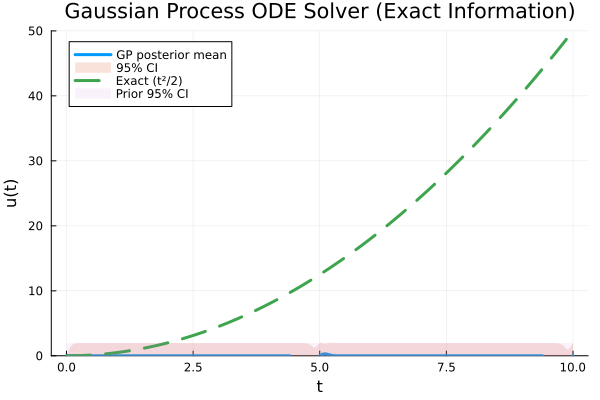

In [7]:
using LinearAlgebra
using Plots

ℓ = 0.1
σf = 1.0
prior_mean = 0.0

# =====================================================
# Cov(u'(ti),u'(tj))
# =====================================================

function K_LL(ts; ℓ=1.0, σf=1.0)

    n = length(ts)
    K = zeros(n,n)

    for i in 1:n
        for j in 1:n

            Δ = ts[i] - ts[j]

            k = rbf_kernel(
                ts[i],
                ts[j];
                ℓ=ℓ,
                σf=σf
            )

            K[i,j] =
                (1/ℓ^2 - Δ^2/ℓ^4) * k
        end
    end

    K
end

# =====================================================
# Observation covariance
#
# observations =
# [u(0), u'(t1), u'(t2), ...]
# =====================================================

function build_observation_covariance(
    ts;
    ℓ,
    σf
)

    n = length(ts)

    K = zeros(n+1,n+1)

    #
    # Cov(u(0),u(0))
    #

    K[1,1] =
        rbf_kernel(
            0.0,
            0.0;
            ℓ=ℓ,
            σf=σf
        )

    #
    # Cov(u(0),u'(tj))
    #

    for j in 1:n

        tj = ts[j]

        k =
            rbf_kernel(
                0.0,
                tj;
                ℓ=ℓ,
                σf=σf
            )

        K[1,j+1] =
            (-tj)/ℓ^2 * k

        K[j+1,1] =
            K[1,j+1]

    end

    #
    # Cov(u',u')
    #

    K[2:end,2:end] .=
        K_LL(
            ts;
            ℓ=ℓ,
            σf=σf
        )

    K
end

# =====================================================
# Cov(u(t),u'(tj))
# =====================================================

function K_starL(
    X_test,
    ts;
    ℓ=1.0,
    σf=1.0
)

    m = length(X_test)
    n = length(ts)

    K = zeros(m,n)

    for i in 1:m
        for j in 1:n

            k =
                rbf_kernel(
                    X_test[i],
                    ts[j];
                    ℓ=ℓ,
                    σf=σf
                )

            K[i,j] =
                (X_test[i]-ts[j]) / ℓ^2 * k
        end
    end

    K
end

# =====================================================
# Cross covariance
# =====================================================

function build_cross_covariance(
    X_test,
    ts;
    ℓ,
    σf
)

    m = length(X_test)
    n = length(ts)

    K = zeros(m,n+1)

    #
    # Cov(u(t),u(0))
    #

    for i in 1:m

        K[i,1] =
            rbf_kernel(
                X_test[i],
                0.0;
                ℓ=ℓ,
                σf=σf
            )

    end

    #
    # Cov(u(t),u')
    #

    K[:,2:end] .=
        K_starL(
            X_test,
            ts;
            ℓ=ℓ,
            σf=σf
        )

    K
end

# =====================================================
# ODE
#
# u'(t)=t
#
# exact:
# u(t)=t^2/2
# =====================================================


t_obs =
    collect(0:dt:10)

t_obs = t_obs[2:end]

rhs =
    collect(t_obs)

y =
    vcat(
        [0.0],
        rhs
    )

# =====================================================
# Posterior
# =====================================================

X_test =
    collect(
        range(
            0,
            10,
            length=500
        )
    )

K =
    build_observation_covariance(
        t_obs;
        ℓ=ℓ,
        σf=σf
    )

#
# numerical jitter only
#

K += 1e-10I

Ks =
    build_cross_covariance(
        X_test,
        t_obs;
        ℓ=ℓ,
        σf=σf
    )

Kss =
    kernel_matrix(
        X_test,
        X_test;
        ℓ=ℓ,
        σf=σf
    )

m_y =
    vcat(
        [prior_mean],
        zeros(length(t_obs))
    )

m_x =
    fill(
        prior_mean,
        length(X_test)
    )

μ =
    m_x +
    Ks * (K \ (y-m_y))

Σ =
    Kss -
    Ks * (K \ Ks')

std =
    sqrt.(max.(diag(Σ),0))

# =====================================================
# Exact solution
# =====================================================

u_exact(t) =
    t^2 / 2

# =====================================================
# Plot
# =====================================================

plot(
    X_test,
    μ,
    lw=3,
    ylim=(0,50),
    label="GP posterior mean"
)

plot!(
    X_test,
    μ .+ 1.96 .* std,
    fillrange=
        μ .- 1.96 .* std,
    fillalpha=0.2,
    linealpha=0,
    label="95% CI"
)

plot!(
    X_test,
    u_exact.(X_test),
    lw=3,
    ls=:dash,
    label="Exact (t²/2)"
)

std_prior =
    sqrt.(
        diag(
            kernel_matrix(
                X_test,
                X_test;
                ℓ=ℓ,
                σf=σf
            )
        )
    )

μ_prior =
    fill(
        prior_mean,
        length(X_test)
    )

plot!(
    X_test,
    μ_prior .+ 1.96 .* std_prior,
    fillrange=
        μ_prior .- 1.96 .* std_prior,
    fillalpha=0.1,
    linealpha=0,
    label="Prior 95% CI"
)

xlabel!("t")
ylabel!("u(t)")
title!("Gaussian Process ODE Solver (Exact Information)")

display(current())

In [123]:
ℓ_grid = [0.1, 0.5, 1.0, 3.0, 5.0, 10.0, 50.0, 100.0]

σf_grid = [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100, 1000]

prior_mean = 0.0

scores = zeros(length(ℓ_grid), length(σf_grid))

# ==========================================
# Grid Search
# ==========================================

for (i, ℓ) in enumerate(ℓ_grid)
    for (j, σf) in enumerate(σf_grid)

        scores[i, j] =
            log_marginal_extended_exact(
                t_obs,
                y;
                ℓ=ℓ,
                σf=σf,
                prior_mean=prior_mean,
                prior_noise=1e-10
            )

    end
end

for (j, σf) in enumerate(σf_grid)

    println()
    println("========================================")
    println("σf = ", σf)
    println("========================================")

    println(rpad("ℓ", 10), "score")

    for (i, ℓ) in enumerate(ℓ_grid)
        println(rpad(string(ℓ), 10), round(scores[i, j], digits=4))
    end
end

best_linear_idx = argmax(scores)
best_i, best_j = Tuple(CartesianIndices(scores)[best_linear_idx])

best_ℓ = ℓ_grid[best_i]
best_σf = σf_grid[best_j]

println()
println("Best parameters")
println("----------------")
println("best ℓ    = ", best_ℓ)
println("best σf   = ", best_σf)
println("best score = ", scores[best_i, best_j])


σf = 0.01
ℓ         score
0.1       -6243.5464
0.5       -156240.2885
1.0       -625033.0411
3.0       -1.09710341809e7
5.0       -2.29918252321e7
10.0      -8.04509802532e7
50.0      -1.36015204032042e10
100.0     -5.33336284933003e10

σf = 0.03
ℓ         score
0.1       -691.2868
0.5       -17354.7341
1.0       -69441.6433
3.0       -1.2190157719e6
5.0       -2.5547282162e6
10.0      -8.9404755592e6
50.0      -1.8157370538865e9
100.0     -1.97026051395479e10

σf = 0.1
ℓ         score
0.1       -62.9542
0.5       -1559.7354
1.0       -6246.2962
3.0       -109705.9661
5.0       -229919.821
10.0      -804649.9302
50.0      -1.672894686684e8
100.0     -2.4490080234522e9

σf = 0.3
ℓ         score
0.1       -10.6945
0.5       -174.1423
1.0       -693.639
3.0       -12186.9986
5.0       -25543.1421
10.0      -89400.7473
50.0      -1.86265648242e7
100.0     -2.815919712816e8

σf = 1.0
ℓ         score
0.1       -7.987
0.5       -19.7681
1.0       -65.2613
3.0       -1097.451
5.0       -2298.